# Exploring revisions to the survey footprint in the Galactic plane

In [30]:
from os import path
import rubin_sim.maf as maf
from rubin_sim.data import get_data_dir, get_baseline, data_dict
import numpy as np
import healpy as hp
import copy
import matplotlib.pyplot as plt
%matplotlib inline
from astropy.coordinates import SkyCoord, Galactic
from astropy import units as u
from astropy.io import fits
from astropy.table import Table, Column
from astropy_healpix import HEALPix
import json
import shapely
import map_transformations
from mw_plot import MWSkyMap

## Compare current baseline with Galactic plane priority map

First let's load the current baseline (v5.3) and calculate the number of visits per healpixel in order to get the footprint information.

In [2]:
opsdb = '/Users/rstreet/rubin_sim_data/sim_baseline/baseline_v5.3.0_10yrs.db'
runName = path.basename(opsdb).replace('.db','')
print(runName)

baseline_v5.3.0_10yrs


In [3]:
NSIDE = 64
NPIX = hp.nside2npix(NSIDE)
outDir = '/Users/rstreet/LSST/SCOC/Survey_Footprint'

bundleList = []
metric1 = maf.metrics.CountMetric(col='observationStartMJD', metric_name='Nvisits')
constraint = 'fiveSigmaDepth > 21.5'
slicer = maf.slicers.HealpixSlicer(nside=NSIDE, use_cache=False)
plotDict = {'colorMax': 950}

bundle = maf.MetricBundle(metric1, slicer, constraint, run_name=runName, plot_dict=plotDict)
bgroup = maf.MetricBundleGroup({'nvisits': bundle}, opsdb, out_dir=outDir, results_db=None)

bgroup.run_all()

Healpix slicer using NSIDE=64, approximate resolution 54.967783 arcminutes


/var/folders/1d/5hlyfsgd0kl_nd815xmp9cv00000gn/T/ipykernel_24258/2054544274.py:5: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


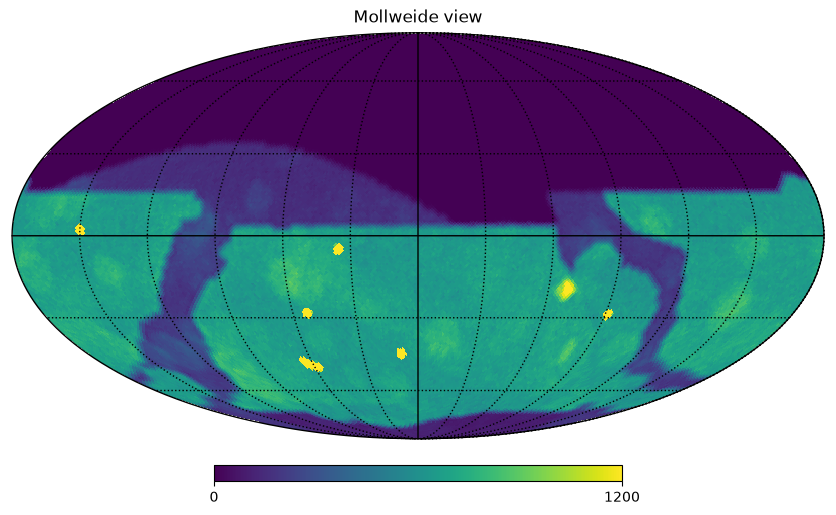

In [4]:
baseline_nvisits = bgroup.bundle_dict['nvisits'].metric_values.filled(0.0)
fig = plt.figure(1,(10,10))
hp.mollview(baseline_nvisits, min=0, max=1200)
hp.graticule()
plt.tight_layout()
plt.close(1)

In [5]:
# Transform the baseline map to galactic coordinates
baseline_map_gal = map_transformations.rotateHealpix(baseline_nvisits, transf=['G', 'C'])

In [6]:
# Normalize this map so that we can overlay another map and have distinctive colors 
#baseline_nvisits /= baseline_nvisits.max()
#baseline_nvisits *= 1200

Now load the Galactic plane priority map.

In [7]:
home = path.expanduser("~")
galSciencePriorityMapFile = path.join(home, 'software/LSST-TVSSC_software_tools/footprint_maps/priority_GalPlane_footprint_map_data_sum.fits')

with fits.open(galSciencePriorityMapFile) as hdul:
    galSciencePriorityMapTable = hdul[1].data

# The sum priority map sums the priority assigned to all HEALpixels over all 6 LSST filters.  
# For ease of explanation, it is valid to average this over all 6 filters here.  
# We also select the combined region map, as opposed to the maps for the distinct science cases
combined_map = getattr(galSciencePriorityMapTable, 'combined_map')
combined_map /= 6

The priority data in the map can be used to select broader or narrower footprints by 'tuning' the priority_threshold.

In [12]:
priority_threshold = 0.05

map_pixels = np.where(combined_map > priority_threshold)[0]
print('Number of HEALpixels in desired survey region with priority > '+str(priority_threshold)+': '+str(len(map_pixels)))
selected_map = np.zeros(len(combined_map))
selected_map[map_pixels] = combined_map[map_pixels] * 1200

Number of HEALpixels in desired survey region with priority > 0.05: 6598


In [13]:
# Transform the priority map to galactic coordinates
#priority_map_gal = map_transformations.rotateHealpix(selected_map, transf=['G', 'C'])
#hp.mollview(priority_map_gal, min=0)
#hp.graticule()

Now overplot the baseline nvisits map with the priority regions highlighted

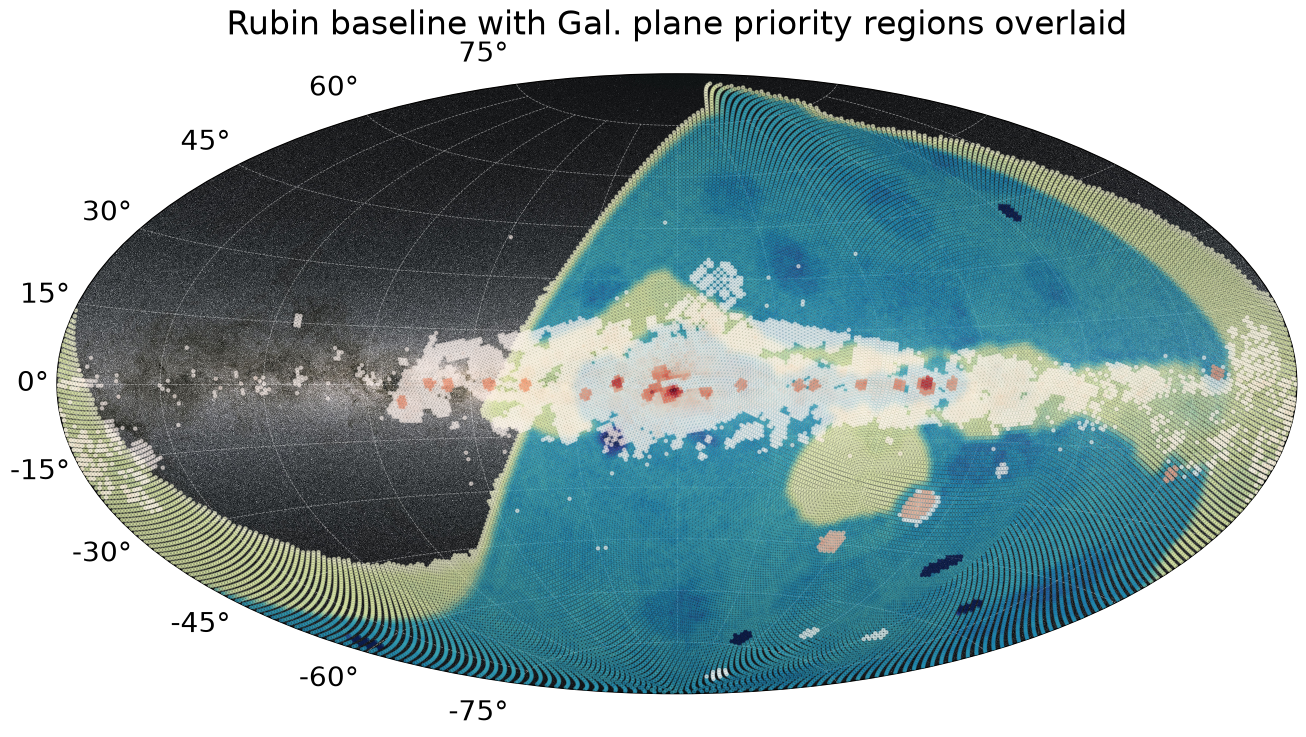

In [37]:
mw1 = MWSkyMap(projection='aitoff', grayscale=False, grid='galactic', background='optical', figsize=(16,10))
plt.rcParams.update({'font.size': 20})
mw1.title = 'Rubin baseline with Gal. plane priority regions overlaid'
proj = HEALPix(nside=NSIDE, order='ring', frame='icrs')

# Plot Rubin footprint
pixels = np.where(baseline_nvisits > 0.0)[0]
s = proj.healpix_to_skycoord(pixels)
plot_visits = copy.deepcopy(baseline_nvisits)
plot_visits[plot_visits > 1200] = 1200
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c=plot_visits[pixels], cmap='YlGnBu', s=5, alpha=0.5)

# Plot priority map 
pixels = np.where(selected_map > 0.0)[0]
s = proj.healpix_to_skycoord(pixels)
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c=selected_map[pixels], cmap='Reds', s=5, alpha=0.5)
plt.savefig(path.join(home, 'software/LSST-TVSSC_software_tools/revised_footprint_maps/rubin_baseline_galplane_priority_map.png'))

### ! Important: the scaling of both maps is arbitrary and should be considered relative

Comparing the priority map with the Galactic plane region covered at "WFD-level" cadence, it includes somewhat more area in the northern plane/bulge around b~+12-15 deg than is actually prioritized in the requested footprint.  

Also note that the two priority regions at the far right of the plane and somewhat away from it are prioritized solely from Sara Bonito's map of Star Forming regions of interest.  This list includes 5 regions of which the other 3 are in the main priority region. 

In the interests of contiguity the southern bulge/plane is generally considered to be a higher priority and joins the extra-galactic WFD. 

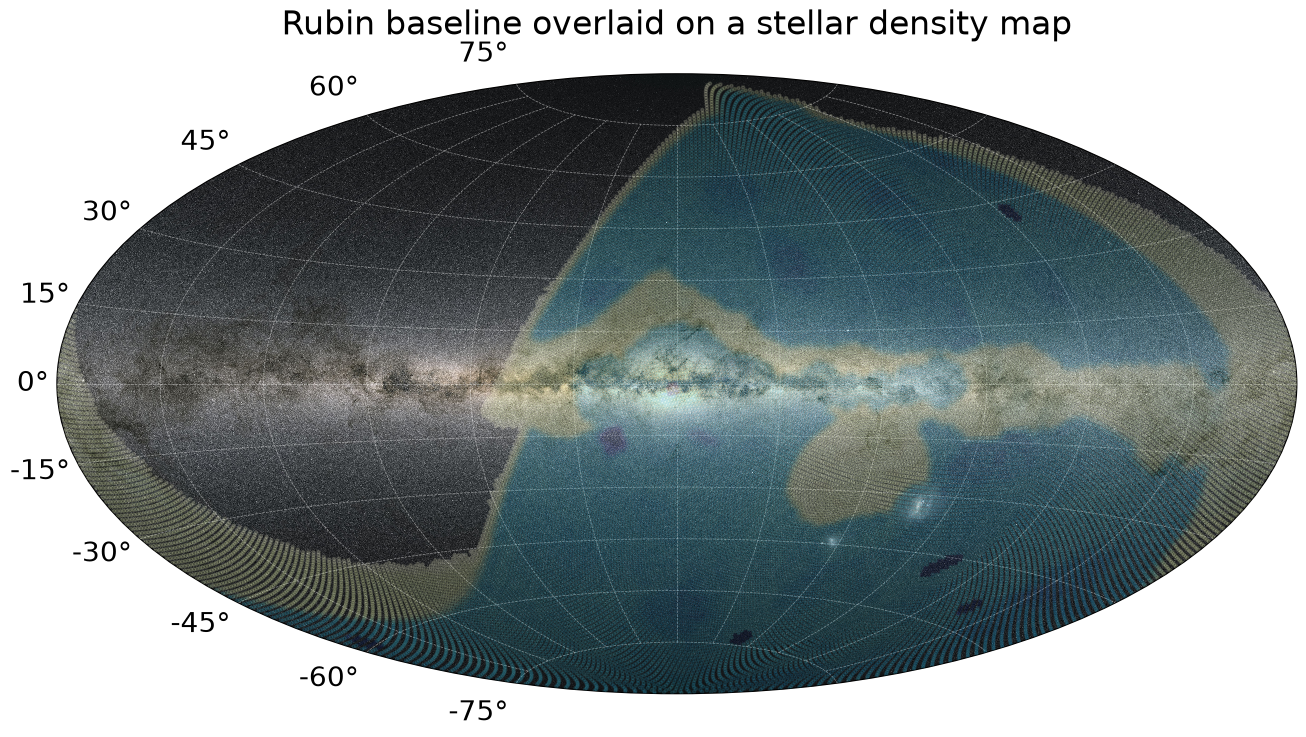

In [48]:
mw1 = MWSkyMap(projection='aitoff', grayscale=False, grid='galactic', background='optical', figsize=(16,10))
plt.rcParams.update({'font.size': 20})
mw1.title = 'Rubin baseline overlaid on a stellar density map'
proj = HEALPix(nside=NSIDE, order='ring', frame='icrs')

# Plot Rubin footprint
pixels = np.where(baseline_nvisits > 0.0)[0]
s = proj.healpix_to_skycoord(pixels)
plot_visits = copy.deepcopy(baseline_nvisits)
plot_visits[plot_visits > 1200] = 1200
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c=plot_visits[pixels], cmap='YlGnBu', s=5, alpha=0.15)
plt.savefig(path.join(home, 'software/LSST-TVSSC_software_tools/revised_footprint_maps/rubin_baseline_map.png'))

By overlaying the Rubin baseline map on an optical map of the sky, we can see that the main region of the Galactic plane survey includes some regions of high extinction in the northern bulge (b~12+ deg).  Similar areas of high extinction have been included.  
One possible footprint adjustment could be to weight the stellar density component of the priority map higher, and focus on the regions where the stars are.  

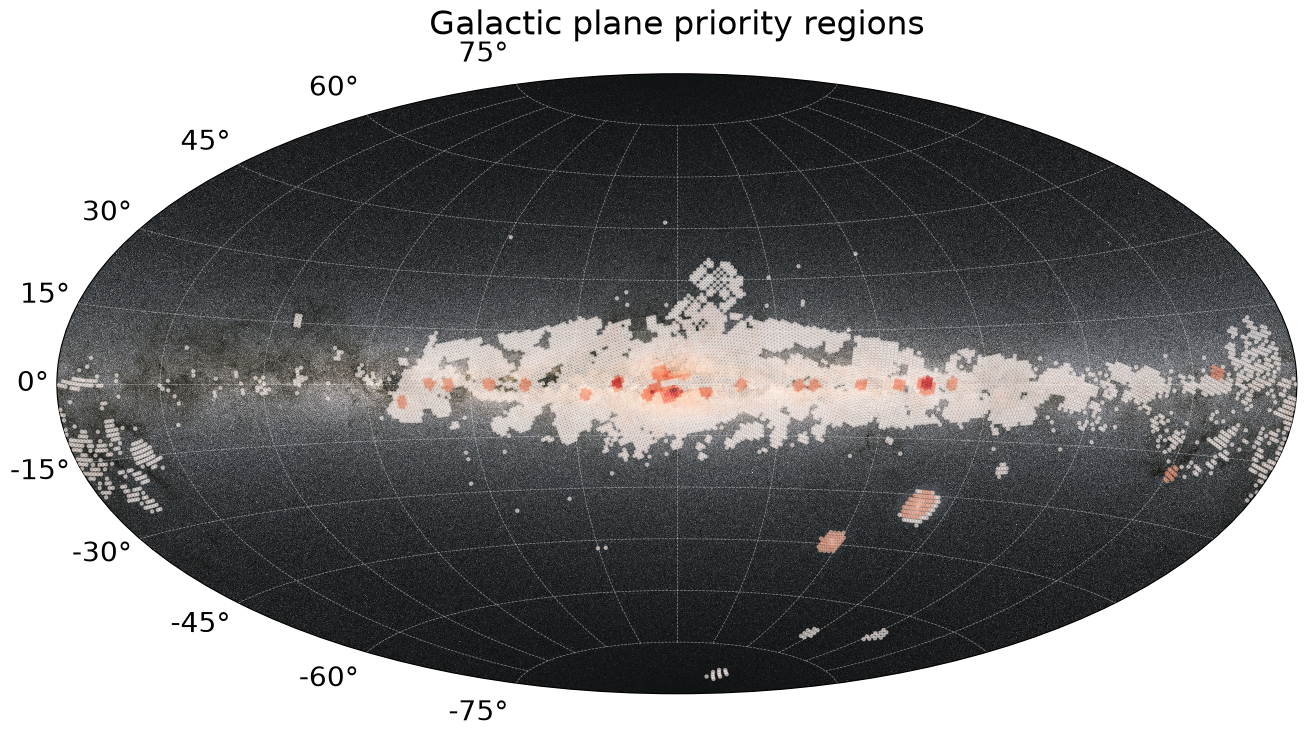

In [40]:
mw1 = MWSkyMap(projection='aitoff', grayscale=False, grid='galactic', background='optical', figsize=(16,10))
plt.rcParams.update({'font.size': 20})
mw1.title = 'Galactic plane priority regions'
proj = HEALPix(nside=NSIDE, order='ring', frame='icrs')

# Plot priority map 
pixels = np.where(selected_map > 0.0)[0]
s = proj.healpix_to_skycoord(pixels)
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c=selected_map[pixels], cmap='Reds', s=5, alpha=0.5)
plt.savefig(path.join(home, 'software/LSST-TVSSC_software_tools/revised_footprint_maps/galplane_priority_map_0.05.png'))

## Tunable areas of priority 
By adjusting the threshold used to slice the priority map, we can adjust the total area selected.

Number of HEALpixels in desired survey region with priority > 0.1: 1238


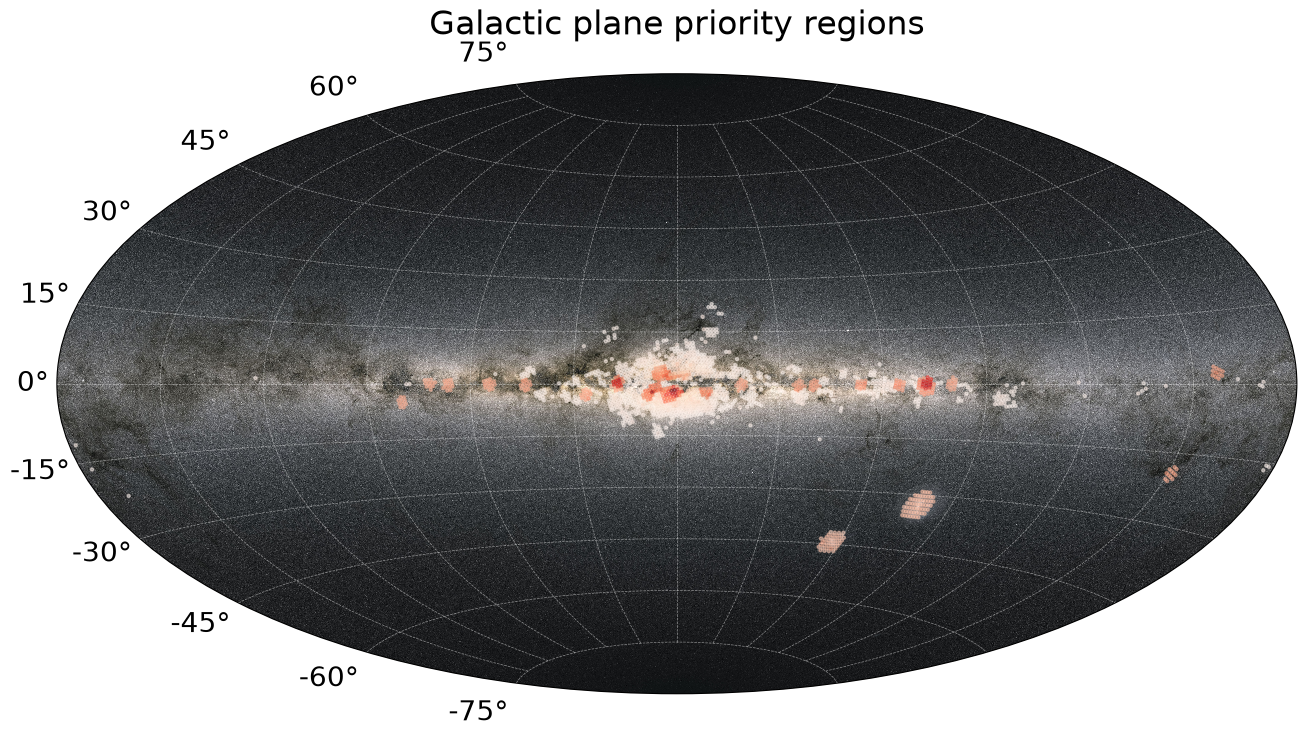

In [47]:
priority_threshold = 0.1

map_pixels = np.where(combined_map > priority_threshold)[0]
print('Number of HEALpixels in desired survey region with priority > '+str(priority_threshold)+': '+str(len(map_pixels)))
selected_map1 = np.zeros(len(combined_map))
selected_map1[map_pixels] = combined_map[map_pixels]

mw1 = MWSkyMap(projection='aitoff', grayscale=False, grid='galactic', background='optical', figsize=(16,10))
plt.rcParams.update({'font.size': 20})
mw1.title = 'Galactic plane priority regions'
proj = HEALPix(nside=NSIDE, order='ring', frame='icrs')

# Plot priority map 
pixels = np.where(selected_map1 > 0.0)[0]
s = proj.healpix_to_skycoord(pixels)
mw1.scatter(s.ra.deg * u.deg, s.dec.deg * u.deg, c=selected_map1[pixels], cmap='Reds', s=5, alpha=0.5)
plt.savefig(path.join(home, 'software/LSST-TVSSC_software_tools/revised_footprint_maps/galplane_priority_map_'+str(priority_threshold)+'.png'))